# <br>

<img src="logo_UNSAM.jpg" align="right" width="180" /> 

<br><br><br>

<h3 align="center">Análisis y Procesamiento de Señales</h3>

<h1 align="center"><b>TS7 -Filtrado Digital de Señales Biomédicas (ECG)</b></h1>
<h3 align="center">Olivia Weihmuller, Luz Romero Marchione y Paloma Ribnikar Diaz</h3>


## Objetivos

Como objetivo principal de este trabajo semanal tenemos el diseño y aplicación de distintos filtros digitales con el fin de mitigar distintas fuentes de contaminación para un registro electrocardiográfico (ECG), entre ellas:
- Ruido generado por el movimiento de los electrodos (alta frecuencia).
- Ruido muscular (alta frecuencia).
- Movimiento de la línea de base del ECG, inducido por la respiración (baja frecuencia).


## Introducción

### Señal analizada
Un electrocardiograma (ECG) corresponde a una señal que registra la actividad eléctrica del corazón a lo largo del tiempo. Estos cambios, producto de la contracción y relajación del corazón, se pueden medir mediante electrodos colocados sobre la piel. En el registro, aparecen las ondas mencionadas a continuación (es trascendental entender su importancia ya que, con la incorporación del filtro buscamos eliminar las interferencias que contaminan el ECG sin destruir la información que nos interesa):
- **Onda P**: Actividad eléctrica asociada a la despolarización de las aurículas.
- **Complejo QRS**: Despolarización de los ventrículos.
- **Onda T**: Repolarización ventricular.
- **Línea Isoeléctrica**: Nivel de referencia que representa ausencia de diferencia de potencial detectable.

<div align="center">
  <img src="imagenformaonda.jpeg" alt="Ondas del ECG" width="450"/>
  <br>
</div>

La señal que medimos en la práctica no es pura, sino que tiene el ECG mezclado con ruidos:

$$x(t) = \text{ECG} + \text{ruido lento} + \text{ruido rápido}$$

Para ver cómo se manifiestan estas interferencias, cargamos y graficamos el registro real de ECG:


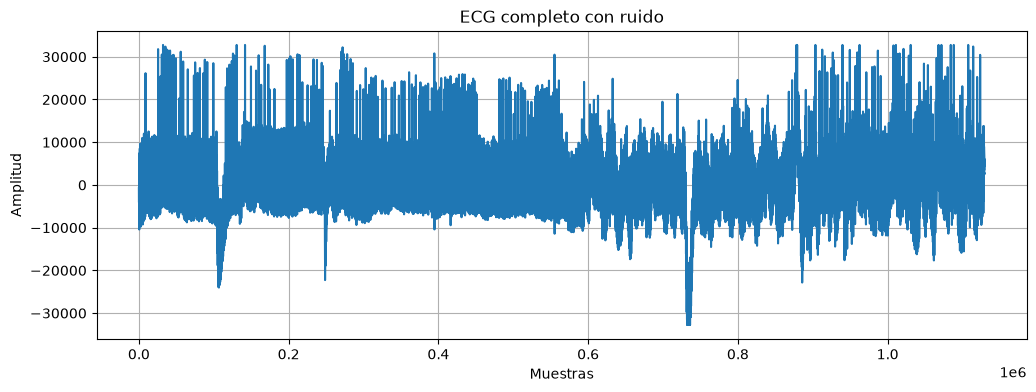

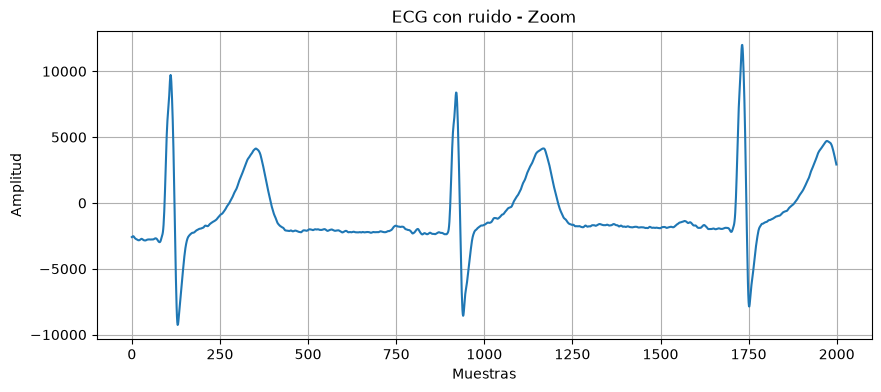

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle

plt.close('all')

#%% Lectura de ECG

fs_ecg = 1000  # Hz

# Cargar ECG con ruido
mat_struct = sio.loadmat('ecg.mat')

ecg_one_leadruido = mat_struct['ecg_lead'].flatten()
#.flatten() transforma la matriz en un vector unidimensional

# Graficar señal original COMPLETA
plt.figure(figsize=(12, 4))
plt.plot(ecg_one_leadruido)
plt.title('ECG completo con ruido')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Graficar un tramo de la señal original (zoom)
plt.figure(figsize=(10, 4))
plt.plot(ecg_one_leadruido[5000:7000])
plt.title('ECG con ruido - Zoom')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid()
plt.show()


### Filtro pasa-banda y diseño de la plantilla

Al observar los gráficos del ECG original, se aprecian claramente los dos tipos de ruido:
1. Una oscilación muy lenta que desplaza la línea de base a lo largo de todo el registro (respiración).
2. Oscilaciones rápidas sobre los latidos (ruido muscular y de línea).

Por lo tanto, necesitamos un **filtro pasa-banda** que haga lo siguiente:
- Atenuar lo que varía muy lento (la respiración).
- Dejar pasar las frecuencias del latido (ondas P, QRS y T).
- Atenuar lo que varía muy rápido (ruido muscular y los 50 Hz de la red).

<div align="center">
  <img src="imagen.jpeg" alt="Plantilla Pasa Banda" width="600"/>
  <br>
  <em>Figura 2: Plantilla de diseño del filtro pasa-banda.</em>
</div>

Definimos las frecuencias de corte de la plantilla:
- **ws1 = 0.1 Hz:** corta los ruidos muy lentos (la respiración).
- **wp1 = 1 Hz:** empieza a dejar pasar el ECG.
- **wp2 = 35 Hz:** hasta acá dejamos pasar el ECG.
- **ws2 = 50 Hz:** corta los ruidos rápidos (músculo y los 50 Hz de la red).

En la TS5 se estimó que aproximadamente el 95% de la potencia del ECG estaba contenido por debajo de 22.8 Hz, por eso elegimos 35 Hz para tener margen y no perder información útil del latido.

#### Bandas de transición y tolerancias:
- **Transición inferior:** de 0.1 a 1 Hz (ancho: **0.9 Hz**).
- **Transición superior:** de 35 a 50 Hz (ancho: **15 Hz**).

Acá podemos observar que la transición inferior resultó mucho más exigente, ya que pasar de atenuar frecuencias a conservar ocurre en apenas **0.9 Hz** frente a una frecuencia de muestreo de 1000 Hz. Esto condiciona fuertemente el orden de los filtros.

Para las atenuaciones establecemos:
- En la banda pasante: atenuación máxima de **Gpass = 3 dB**.
- En las bandas de rechazo: atenuación mínima de **Gstop = 40 dB**.


## Diseño de los filtros IIR: Infinite Impulse Response

En un filtro IIR, la salida no depende únicamente de las muestras actuales y anteriores de la entrada: también depende de salidas anteriores del propio filtro (posee realimentación):

$$y[n] = \sum_{k=0}^{M} b_k x[n-k] - \sum_{k=1}^{N} a_k y[n-k]$$

Para cumplir la plantilla evaluamos tres aproximaciones clásicas:
- **Butterworth:** Respuesta de máxima planicidad en banda pasante, sin ondulaciones (ripple), pero requiere mayor orden.
- **Chebyshev II:** Banda pasante monótona y rizado en la banda de rechazo, logrando transiciones más abruptas con menor orden.
- **Cauer (Elíptico):** Presenta rizado tanto en la banda pasante como en la de rechazo, logrando el menor orden posible para cumplir las cotas.

### Implementación en secciones de segundo orden (SOS) y filtrado bidireccional

Una de las dificultades de la implementación de los filtros IIR es su sensibilidad a los errores numéricos, especialmente en filtros de orden elevado. Los errores de representación y redondeo pueden alterar el comportamiento del sistema y comprometer su estabilidad.

Para reducir estos problemas se utilizó el formato **SOS (Second-Order Sections)**, que representa el filtro mediante una cascada de secciones de segundo orden. Esta implementación no modifica el orden total del filtro diseñado, sino que permite realizar los cálculos de manera numéricamente más robusta.

Además, los filtros IIR se aplicaron mediante `sosfiltfilt()`, realizando un filtrado hacia adelante y hacia atrás. De esta manera se obtiene una respuesta efectiva de **fase cero y retardo de grupo nulo**, evitando el desfase neto de las componentes del ECG y garantizando que los complejos QRS no queden desplazados temporalmente (a costa de utilizar un procedimiento no causal).

**Observación sobre la atenuación:** Cuando aplicamos dos veces un filtro, sus respuestas en magnitud se multiplican (en dB se suman). Razón por la cual en el código dividimos `Gpass` y `Gstop` por dos (`Gpass/2` y `Gstop/2`), para compensar esta ganancia y que al pasar dos veces la señal por el filtro el resultado cumpla con los 3 dB y 40 dB de la plantilla.


In [142]:
#%% Diseño de los filtros IIR

wp1 = 1    #[Hz]
ws1 = 0.1  #[Hz]
wp2 = 35   #[Hz]
ws2 = 50   #[Hz]

Gpass = 3  #[dB]
Gstop = 40 #[dB]

ripple = Gpass
att = Gstop

# Diseñamos con Gpass/2 y Gstop/2 por el sosfiltfilt (filtrado bidireccional)
sos_butt = sig.iirdesign(
    [wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2,
    ftype='butter', fs=fs_ecg, output='sos'
)

sos_cheby2 = sig.iirdesign(
    [wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2,
    ftype='cheby2', fs=fs_ecg, output='sos'
)

sos_cauer = sig.iirdesign(
    [wp1, wp2], [ws1, ws2], Gpass/2, Gstop/2,
    ftype='cauer', fs=fs_ecg, output='sos'
)

# Mostramos cuántas SOS y qué orden tiene cada filtro
print(f"Butterworth:   {sos_butt.shape[0]} SOS  -> Orden total: {sos_butt.shape[0]*2}")
print(f"Chebyshev II:  {sos_cheby2.shape[0]} SOS  -> Orden total: {sos_cheby2.shape[0]*2}")
print(f"Cauer:         {sos_cauer.shape[0]} SOS  -> Orden total: {sos_cauer.shape[0]*2}")


Butterworth:   8 SOS  -> Orden total: 16
Chebyshev II:  4 SOS  -> Orden total: 8
Cauer:         3 SOS  -> Orden total: 6


### Verificación de la plantilla: Resolución del análisis frecuencial

Para verificar el cumplimiento de la plantilla durante el diseño de los filtros, se utilizó un vector de frecuencias `ff` construido combinando `np.logspace()` y `np.linspace()`.

Inicialmente, al evaluar la respuesta en frecuencia con puntos distribuidos uniformemente entre 0 y 500 Hz, la resolución resultaba insuficiente para observar correctamente la transición inferior, comprendida entre **0,1 y 1 Hz**.

Por este motivo, se utilizó `logspace()` para concentrar una mayor cantidad de puntos en las frecuencias bajas y en las regiones de transición, mientras que `linspace()` se reservó para las frecuencias superiores, donde no era necesaria tanta resolución.

Esto permitió visualizar con mayor precisión las oscilaciones y los valores máximos y mínimos de la respuesta. De lo contrario, un filtro podía parecer que cumplía la plantilla simplemente porque la evaluación no incluía suficientes puntos para detectar ciertas desviaciones.

Es importante aclarar que esta modificación no altera los coeficientes ni el funcionamiento del filtro, sino únicamente la resolución con la que se calcula y representa su respuesta en frecuencia.


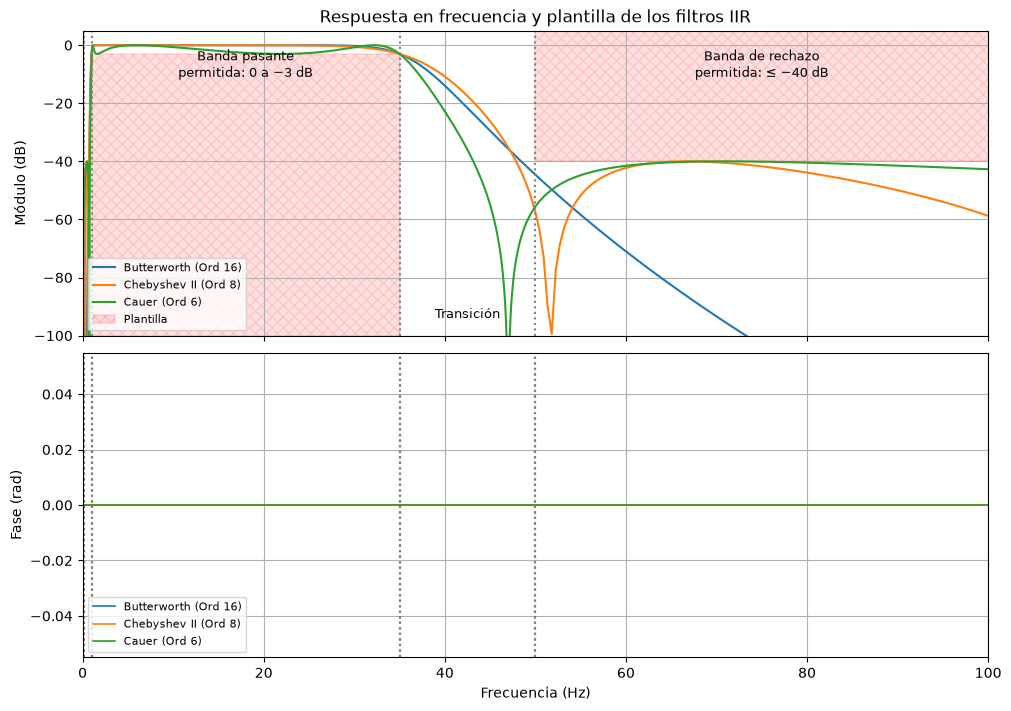

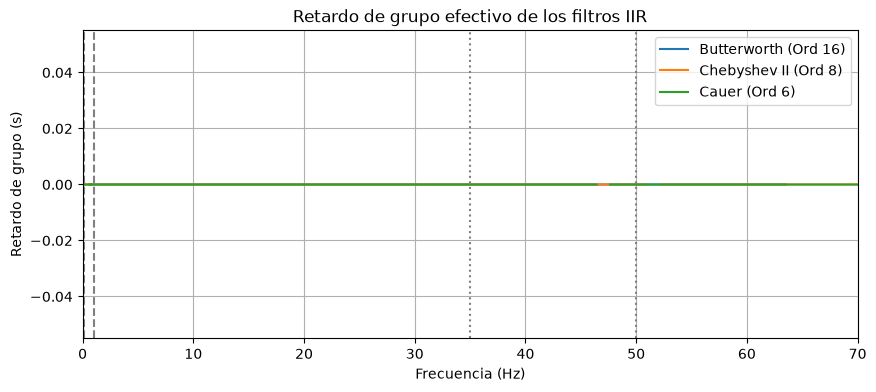

In [143]:
#%% Funciones de visualización y vector ff

y_min, y_max = -100, 5

# Construcción del vector ff combinando logspace y linspace
ff = np.append(
    np.logspace(np.log10(0.001), np.log10(2), 2000),
    np.logspace(np.log10(2.01), np.log10(50), 2000)
)
ff = np.append(ff, np.linspace(50, fs_ecg/2, 1000, endpoint=True))
ff = np.unique(np.append(ff, [0, ws1, wp1, wp2, ws2]))
ff = np.sort(ff)

def calc_freq_sos(sos):
    # Respuesta en frecuencia de una pasada
    f, h = sig.freqz_sos(sos, worN=ff, fs=fs_ecg)

    # Respuesta efectiva de sosfiltfilt (dos pasadas)
    # Se cuadran los módulos y la fase resultante es cero
    h_doble = np.abs(h)**2

    return f, h_doble


def calc_freq_fir(bfir):
    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    resp_freq = sig.freqz(bfir, 1, worN=ff, fs=fs_ecg)
    return resp_freq


def calc_resp(resp_freq, leg_str, fig_n_axes, ax_retardo):
    (f, h) = resp_freq

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega)
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # Módulo
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla de los filtros IIR")
    ax_mod.grid(True)

    # Fase
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for borde in (ws1, wp1, wp2, ws2):
        ax_fase.axvline(borde, color="gray", linestyle=":")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)

    # Retardo
    ax_retardo.plot(f, retardo_s_plot, label=leg_str)

#%% Graficar respuestas de los filtros IIR

fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
fig_retardo, ax_retardo = plt.subplots(figsize=(10, 4))

# Respuestas IIR
calc_resp(calc_freq_sos(sos_butt), 'Butterworth (Ord 16)', fig_n_axes, ax_retardo)
calc_resp(calc_freq_sos(sos_cheby2), 'Chebyshev II (Ord 8)', fig_n_axes, ax_retardo)
calc_resp(calc_freq_sos(sos_cauer), 'Cauer (Ord 6)', fig_n_axes, ax_retardo)

# Ploteo de la plantilla
(fig, (ax_mod, ax_fase)) = fig_n_axes

# Banda pasante
rect_pasante = Rectangle(
    (wp1, y_min), wp2-wp1, -ripple-y_min,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2, label='Plantilla'
)
ax_mod.add_patch(rect_pasante)

# Rechazo inferior
rect_rechazo_inf = Rectangle(
    (0, -att), ws1, y_max+att,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_rechazo_inf)

# Rechazo superior
rect_rechazo = Rectangle(
    (ws2, -att), fs_ecg/2-ws2, y_max+att,
    facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2
)
ax_mod.add_patch(rect_rechazo)

for borde in (ws1, wp1, wp2, ws2):
    ax_mod.axvline(borde, color="gray", linestyle=":")

ax_mod.text((wp1+wp2)/2, y_max-6, "Banda pasante\npermitida: 0 a −3 dB", ha="center", va="top", fontsize=9)
ax_mod.text((ws2+100)/2, y_max-6, "Banda de rechazo\npermitida: ≤ −40 dB", ha="center", va="top", fontsize=9)
ax_mod.text((wp2+ws2)/2, y_min+5, "Transición", ha="center", va="bottom", fontsize=9)

ax_mod.set_xlim(0, 100)
ax_mod.legend(loc="lower left", fontsize=8)
ax_fase.legend(loc="lower left", fontsize=8)

# Retardo
for fc, ls in zip([ws1, wp1, wp2, ws2], ['--', '--', ':', ':']):
    ax_retardo.axvline(fc, color="gray", linestyle=ls)

ax_retardo.set_xlabel("Frecuencia (Hz)")
ax_retardo.set_ylabel("Retardo de grupo (s)")
ax_retardo.set_title("Retardo de grupo efectivo de los filtros IIR")
ax_retardo.set_xlim(0, 70)
ax_retardo.grid(True)
ax_retardo.legend()

plt.show()



### Análisis de los resultados de los filtros IIR

Mirando los gráficos podemos verificar que:
1. **Módulo:**
   - En la banda pasante (entre 1 y 35 Hz), las tres respuestas se mantienen perfectamente entre 0 y -3 dB.
   - En la banda de rechazo inferior (por debajo de 0.1 Hz) y superior (a partir de 50 Hz), la atenuación es inferior a -40 dB, cumpliendo la plantilla impuesta.
   - **Comparación de órdenes:** Para cumplir exactamente la misma plantilla, **Cauer** solo necesitó **orden 6** (3 secciones SOS), **Chebyshev II** necesitó **orden 8** (4 SOS) y **Butterworth** necesitó **orden 16** (8 SOS). Esto muestra la gran eficiencia que tiene Cauer al permitir ripple en ambas bandas.
2. **Fase y retardo de grupo:**
   - La fase efectiva es exactamente **cero** y el retardo de grupo es **cero** en todo el rango gracias a que aplicamos `sosfiltfilt()`. Esto es clave para que ningún complejo QRS se corra de tiempo ni se deforme.


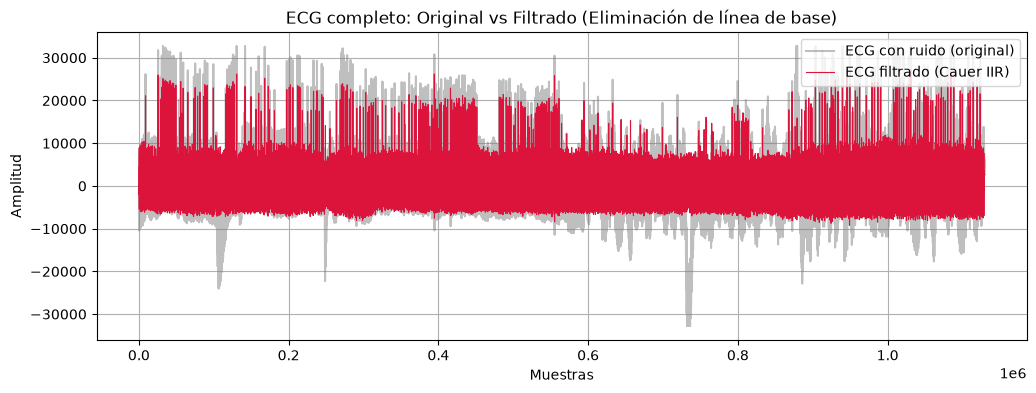

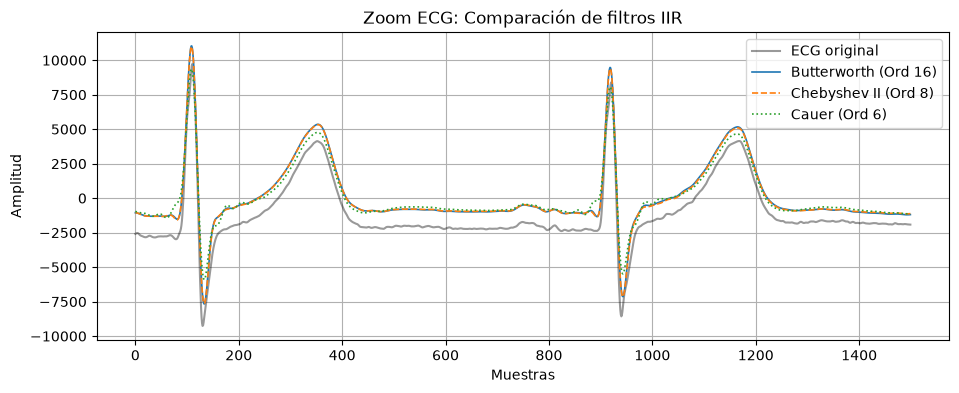

In [144]:
#%% Aplicar filtros IIR al ECG

# Filtrado hacia adelante y hacia atrás con sosfiltfilt
ecg_butt = sig.sosfiltfilt(sos_butt, ecg_one_leadruido)
ecg_cheby2 = sig.sosfiltfilt(sos_cheby2, ecg_one_leadruido)
ecg_cauer = sig.sosfiltfilt(sos_cauer, ecg_one_leadruido)

# Comparación del ECG completo: con ruido vs filtrado
plt.figure(figsize=(12, 4))
plt.plot(ecg_one_leadruido, label='ECG con ruido (original)', alpha=0.5, color='gray')
plt.plot(ecg_cauer, label='ECG filtrado (Cauer IIR)', color='crimson', linewidth=0.8)
plt.title('ECG completo: Original vs Filtrado (Eliminación de línea de base)')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.legend(loc='upper right')
plt.grid()
plt.show()

# Zoom sobre un tramo con latidos
plt.figure(figsize=(11, 4))
plt.plot(ecg_one_leadruido[5000:6500], label='ECG original', alpha=0.4, color='black')
plt.plot(ecg_butt[5000:6500], label='Butterworth (Ord 16)', linewidth=1.2)
plt.plot(ecg_cheby2[5000:6500], label='Chebyshev II (Ord 8)', linewidth=1.2, linestyle='--')
plt.plot(ecg_cauer[5000:6500], label='Cauer (Ord 6)', linewidth=1.2, linestyle=':')
plt.title('Zoom ECG: Comparación de filtros IIR')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.legend(loc='upper right')
plt.grid()
plt.show()


### Conclusiones del diseño IIR

1. **Cumplimiento de la plantilla:** Tanto Butterworth, Chebyshev II como Cauer cumplen las restricciones de la plantilla en todas las bandas.
2. **Comparación de complejidad:** Cauer resultó el más eficiente en términos de orden (orden 6, 3 biquads) frente a Chebyshev II (orden 8, 4 biquads) y Butterworth (orden 16, 8 biquads).
3. **Estabilidad numérica y fase cero:** La implementación SOS permitió reducir la sensibilidad a los errores numéricos, mientras que sosfiltfilt() proporcionó una respuesta efectiva de fase cero, evitando el desplazamiento temporal neto de los complejos QRS. Sin embargo, esto no garantiza que sus amplitudes y formas permanezcan completamente inalteradas.
A continuación, mis compañeras presentan el diseño de los filtros FIR para contrastar su desempeño frente a estos IIR.


### Filtros FIR: Finite Impulse Response

A diferencia del IIR, un filtro FIR tiene una respuesta al impulso de duración finita y no utiliza salidas anteriores para calcular la salida actual (no posee realimentación).

Su ecuación general es:

$$y[n] = \sum_{k=0}^{N-1} b_k x[n-k]$$

En este trabajo mis compañeras van a utilizar tres métodos de diseño:
- **Ventana Hann:** Diseña el filtro mediante una respuesta ideal multiplicada por una ventana.
- **firls:** Minimiza el error cuadrático integrado.
- **remez:** Minimiza el máximo error ponderado (minimax).



### Diseño de filtros FIR

Para el diseño de los filtros FIR se utilizaron tres metodologías: **ventanas, cuadrados mínimos y Parks-McClellan**. En todos los casos se buscó cumplir la misma plantilla de diseño establecida previamente, para atenuar las interferencias del ECG sin alterar significativamente su morfología.

Se diseñaron **filtros FIR de fase lineal tipo I**, caracterizados por presentar una cantidad impar de coeficientes y una respuesta al impulso simétrica: $
h[n] = h[N-1-n]
$

Esta simetría permite obtener un retardo de grupo constante:

$$
\tau_g = \frac{N-1}{2}
$$

donde $N$ representa la cantidad de coeficientes (*taps*) y el retardo se expresa en muestras.

La fase lineal es especialmente importante en el procesamiento de ECG, ya que evita que las distintas componentes frecuenciales de la banda útil experimenten retardos diferentes. Esto favorece la conservación de las relaciones temporales entre las ondas P, QRS y T.

Sin embargo, aumentar la cantidad de coeficientes también incrementa el retardo y el costo computacional. Por este motivo, se buscó que cada método cumpliera la plantilla utilizando la menor cantidad de taps posible dentro de los diseños evaluados.

A continuación, se presentan los tres métodos utilizados y los ajustes realizados para alcanzar las especificaciones establecidas.



### Método de ventanas

El primer método utilizado fue el **diseño FIR mediante ventanas**, implementado con la función `firwin2()` de `scipy.signal`.

A diferencia de `firwin()`, que permite diseñar filtros a partir de sus frecuencias de corte, `firwin2()` permite especificar una respuesta deseada mediante dos vectores: uno con las **frecuencias** y otro con las **ganancias** correspondientes. La función recibe además la cantidad de coeficientes (`numtaps`), la ventana seleccionada (`window`) y la frecuencia de muestreo (`fs`), y devuelve los coeficientes del filtro FIR.

Se consideraron distintas ventanas, como **rectangular (Boxcar), Hamming y Hann**, que se diferencian por la forma en que ponderan los coeficientes y, por lo tanto, por su efecto sobre las oscilaciones y la atenuación en frecuencia.

Durante las pruebas, la mayor dificultad estuvo asociada a la **transición inferior**, comprendida entre 0,1 y 1 Hz, debido a su estrecho intervalo de frecuencias.

Para mejorar el cumplimiento se recurrió a una estrategia de **predistorsión de la plantilla**. Se definió una frecuencia auxiliar `ws1_modif`, que se fue ajustando hasta establecerla en 0,5 Hz. De esta manera, se le solicita al algoritmo mantener la ganancia deseada nula hasta 0,5 Hz en lugar de 0,1 Hz, imponiendo una condición de diseño más exigente. Esto permite mejorar la atenuación en la banda de rechazo inferior sin modificar la plantilla original utilizada para la evaluación.

Otro parámetro que se fue ajustando fue la **cantidad de coeficientes (taps)**, buscando un compromiso entre el cumplimiento de las especificaciones y el costo computacional, manteniendo siempre una cantidad impar de coeficientes para obtener filtros FIR de tipo I.

Finalmente, se compararon las ventanas Boxcar, Hamming y Hann utilizando **2651 taps y las mismas frecuencias de diseño**, de modo que las diferencias observadas respondieran únicamente a la ventana utilizada.


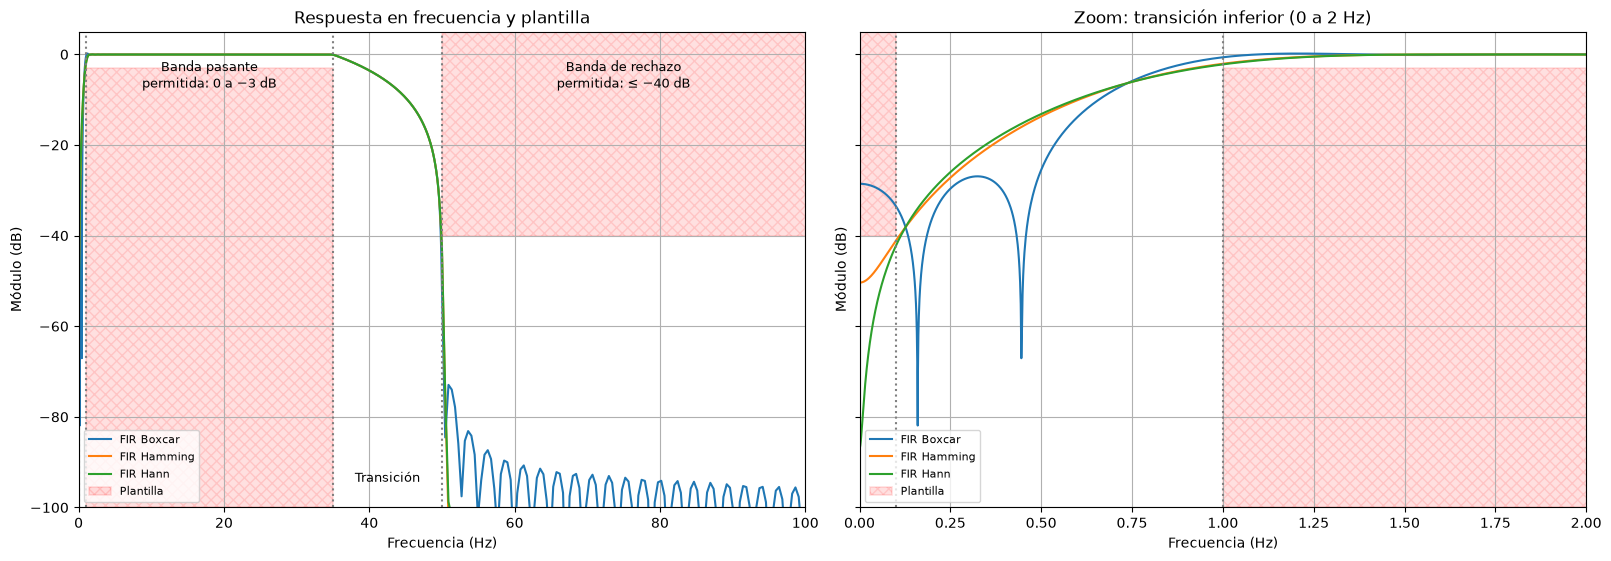

In [145]:

# FIR DESIGN

# Si elijo tipo 2, el problema es la simetría porque quiero demora entera.
# Preferimos N impar para obtener un retardo entero.

taps_win_hamm = 2651
taps_win_box = 2651
taps_win_hann = 2651
delta_w = 5

# Filtro FIR por ventanas
ws1_modif = 0.5

b_win_hann = sig.firwin2(
    taps_win_hann,
    [0.0, ws1_modif, wp1, wp2, ws2, fs_ecg/2],
    [0.0, 0.0, 0.995, 0.995, 0.0, 0.0],
    window='hann', fs=fs_ecg
)


#%% Comparación de ventanas: Boxcar, Hamming y Hann

# Diseños auxiliares para comparar las ventanas
# Mismas frecuencias, ganancias y cantidad de taps

b_boxcar_comp = sig.firwin2(
    taps_win_box,
    [0.0, ws1_modif, wp1, wp2, ws2, fs_ecg/2],
    [0.0, 0.0, 0.995, 0.995, 0.0, 0.0],
    window='boxcar', fs=fs_ecg
)

b_hamming_comp = sig.firwin2(
    taps_win_hamm,
    [0.0, ws1_modif, wp1, wp2, ws2, fs_ecg/2],
    [0.0, 0.0, 0.995, 0.995, 0.0, 0.0],
    window='hamming', fs=fs_ecg
)

#%% Graficar la respuesta de las ventanas

# Dos gráficos: plantilla completa y zoom de la transición inferior
fig, (ax_mod, ax_zoom) = plt.subplots(
    1, 2, figsize=(16, 5.5), sharey=True,
    constrained_layout=True
)

# Respuestas de los filtros FIR por ventanas
filtros_ventanas = [
    (b_boxcar_comp, 'FIR Boxcar'),
    (b_hamming_comp, 'FIR Hamming'),
    (b_win_hann, 'FIR Hann')
]

for b, nombre in filtros_ventanas:

    # Reutilizamos la función original calc_freq_fir()
    f, h = calc_freq_fir(b)

    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    ax_mod.plot(f, modulo_db, linewidth=1.5, label=nombre)
    ax_zoom.plot(f, modulo_db, linewidth=1.5, label=nombre)


# Ploteo de la plantilla en ambos gráficos

for ax in (ax_mod, ax_zoom):

    # Banda pasante: zona no permitida por debajo de -ripple
    rect_pasante = Rectangle(
        (wp1, y_min), wp2-wp1, -ripple-y_min,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2,
        label='Plantilla'
    )
    ax.add_patch(rect_pasante)

    # Banda de rechazo: zona no permitida por encima de -att

    # Rechazo inferior
    rect_rechazo_inf = Rectangle(
        (0, -att), ws1, y_max+att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax.add_patch(rect_rechazo_inf)

    # Rechazo superior
    rect_rechazo = Rectangle(
        (ws2, -att), fs_ecg/2-ws2, y_max+att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax.add_patch(rect_rechazo)

    # Límites de la plantilla
    for borde in (ws1, wp1, wp2, ws2):
        ax.axvline(borde, color="gray", linestyle=":")

    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Módulo (dB)")
    ax.grid(True)
    ax.legend(loc="lower left", fontsize=8)


# --- Gráfico 1: plantilla completa ---

ax_mod.set_title("Respuesta en frecuencia y plantilla")
ax_mod.set_xlim(0, 100)

# Etiquetas de zonas
ax_mod.text(
    (wp1+wp2)/2, y_max-6,
    "Banda pasante\npermitida: 0 a −3 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (ws2+100)/2, y_max-6,
    "Banda de rechazo\npermitida: ≤ −40 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (wp2+ws2)/2, y_min+5,
    "Transición",
    ha="center", va="bottom", fontsize=9
)


# --- Gráfico 2: zoom de la transición inferior ---

ax_zoom.set_title("Zoom: transición inferior (0 a 2 Hz)")
ax_zoom.set_xlim(0, 2)

plt.show()



#### Análisis y selección de la ventana

Al comparar las respuestas en frecuencia, se observa que **Boxcar no alcanza la atenuación requerida en la banda de rechazo inferior**, mientras que Hamming y Hann presentan un comportamiento similar y satisfacen las exigencias de rechazo.

Se seleccionó la **ventana Hann**, ya que, para la misma cantidad de coeficientes, presenta un margen de atenuación ligeramente mayor en bajas frecuencias, justamente la región más exigente de la plantilla.

Como último ajuste, se modificó la **ganancia deseada en la banda pasante de 1 a 0,995**, debido a que la respuesta presentaba una pequeña oscilación que superaba el límite superior de 0 dB. Con esta modificación, se consiguió que el filtro cumpliera todas las restricciones de la plantilla, sin cambiar sus frecuencias de diseño ni su cantidad de coeficientes.

El filtro seleccionado utiliza **2651 taps**, equivalentes a un retardo de grupo constante de **1325 muestras (1,325 s)**. Este diseño se conservará para la comparación posterior con los otros métodos FIR.



### Método de cuadrados mínimos

El segundo filtro FIR se diseñó mediante el **método de cuadrados mínimos**, utilizando la función `firls()` de `scipy.signal`.

A diferencia del método de ventanas, `firls()` calcula los coeficientes buscando minimizar el **error cuadrático integrado** entre la respuesta en frecuencia obtenida y la respuesta deseada. Este error representa cuánto se aleja la ganancia real del filtro de la ganancia que le solicitamos en cada frecuencia.

Una ventaja de este método es que permite incorporar un **vector de pesos (`weight`)**, con el cual podemos darle mayor importancia al cumplimiento de determinadas bandas. En nuestro caso se utilizó `weight=[500, 5, 500]`, correspondiente al rechazo inferior, la banda pasante y el rechazo superior, respectivamente. Esto significa que el algoritmo penaliza 100 veces más los errores en las bandas de rechazo que en la banda pasante, buscando que la ganancia se mantenga lo más cercana posible a cero en las frecuencias que queremos eliminar.

Durante las pruebas se observó que la respuesta en frecuencia presentaba picos y oscilaciones importantes cerca de la transición superior, dificultando el cumplimiento de la plantilla. Esto ocurre porque `firls()` minimiza el error solamente en las bandas que le especificamos, mientras que en los intervalos de transición no se impone directamente una condición sobre la ganancia.

Para controlar estas oscilaciones, se modificaron las frecuencias superiores utilizadas en el diseño. Inicialmente se buscaba mantener la ganancia cercana a 1 hasta 35 Hz y comenzar la banda de rechazo desde 50 Hz, dejando 15 Hz para que la respuesta descendiera entre ambas bandas.

Luego se establecieron `wp2_diseno_ls = 43 Hz` y `ws2_diseno_ls = 45 Hz`. De esta manera, se le solicita al algoritmo mantener la ganancia de la banda pasante hasta 43 Hz y comenzar la banda de rechazo desde 45 Hz. Así, el intervalo en el que la respuesta puede realizar la transición sin restricciones directas se reduce de 15 Hz a solamente 2 Hz, ayudando a controlar los picos que aparecían en esa región.

Estas modificaciones corresponden únicamente al diseño del filtro: la plantilla original, con banda pasante hasta 35 Hz y rechazo desde 50 Hz, permanece sin cambios para verificar el resultado.

También se ajustó la ganancia deseada en la banda pasante a 0,98, ligeramente por debajo de 1, para permitir pequeñas oscilaciones sin superar el límite superior de 0 dB establecido en la plantilla.

Finalmente, se seleccionaron **2251 taps**, manteniendo una cantidad impar de coeficientes para obtener un filtro FIR de tipo I.


In [146]:

#%% FIR design Least Squares

taps_firls = 2251
wp2_diseno_ls = 43
ws2_diseno_ls = 45

b_firls = sig.firls(
    taps_firls,
    [0.0, ws1, wp1, wp2_diseno_ls, ws2_diseno_ls, fs_ecg/2],
    [0.0, 0.0, 0.98, 0.98, 0.0, 0.0],
    weight=[500.0, 5.0, 500.0],
    fs=fs_ecg
)


#### Análisis del diseño por cuadrados mínimos

Mediante el ajuste de los pesos, las frecuencias de diseño y la ganancia deseada, se obtuvo un filtro FIR de **2251 coeficientes** que cumple con la plantilla establecida: mantiene la ganancia entre −3 y 0 dB en la banda pasante y alcanza una atenuación de al menos 40 dB en ambas bandas de rechazo.

La principal ventaja de este método fue la posibilidad de **asignar diferentes pesos a cada banda**, permitiendo exigir una ganancia más cercana a cero en las frecuencias que queremos rechazar. Además, el ajuste de las frecuencias superiores permitió controlar las oscilaciones que aparecían cerca de la transición, evitando que la respuesta superara los límites permitidos por la plantilla.




### Método de Parks-McClellan (Remez)

El tercer filtro FIR se diseñó mediante el **método de Parks-McClellan**, utilizando la función `remez()` de `scipy.signal`.

A diferencia del método de cuadrados mínimos, que busca reducir el error cuadrático total, Parks-McClellan utiliza el criterio **minimax**: busca minimizar el mayor error entre la respuesta en frecuencia obtenida y la respuesta deseada, teniendo en cuenta los pesos asignados a cada banda.

Este procedimiento permite obtener una respuesta **equiripple**, caracterizada por presentar oscilaciones cuyos errores máximos ponderados tienen aproximadamente la misma magnitud y alternan de signo. Esta característica es similar a la de los filtros IIR Cauer, aunque ambos métodos utilizan estructuras diferentes.

La función `remez()` recibe la cantidad de coeficientes (`numtaps`), los límites de las bandas (`bands`), la ganancia deseada en cada una (`desired`), los pesos (`weight`) y la frecuencia de muestreo (`fs`). A partir de estos parámetros calcula iterativamente los coeficientes del filtro.

Durante nuestras primeras pruebas aparecieron problemas numéricos al utilizar cantidades elevadas de coeficientes, obteniendo respuestas en frecuencia que no representaban correctamente el comportamiento pasabanda buscado. Esto puede deberse a que al tratarse de un algoritmo iterativo, no siempre se garantiza una convergencia adecuada.

Para obtener un diseño satisfactorio se ajustaron la cantidad de coeficientes, los pesos y las frecuencias superiores utilizadas por el algoritmo.

Al igual que en cuadrados mínimos, se establecieron las frecuencias superiores de diseño en **43 Hz y 45 Hz**, buscando controlar las oscilaciones de la respuesta cerca de la transición y mejorar el cumplimiento de la plantilla original.

Se utilizó el vector de pesos `weight=[100, 10, 100]`, que asigna mayor importancia a las bandas de rechazo que a la banda pasante, y se ajustó la **ganancia deseada en paso a 0,9** para mantener las oscilaciones dentro de los límites permitidos.

Finalmente, se obtuvo un diseño de **1251 taps**, manteniendo una cantidad impar de coeficientes para conservar la estructura FIR de tipo I.


In [147]:

#%% FIR design Parks-McClellan

taps_remez = 1251

b_remez = sig.remez(
    taps_remez,
    [0.0, ws1, wp1, wp2_diseno_ls, ws2_diseno_ls, fs_ecg/2],
    [0.0, 0.9, 0.0],
    weight=[100.0, 10.0, 100.0],
    fs=fs_ecg
)


#### Análisis del diseño por Parks-McClellan

Mediante el ajuste de los parámetros se obtuvo un filtro de **1251 coeficientes** que cumple la plantilla establecida.

La principal ventaja de este método fue alcanzar las especificaciones con menos coeficientes que los otros diseños FIR. Sin embargo, durante las pruebas iniciales presentó dificultades de convergencia, por lo que fue necesario ajustar sus parámetros hasta obtener una respuesta adecuada.



### Verificación de la plantilla de diseño

Una vez diseñados los tres filtros FIR, se compararon sus respuestas en frecuencia utilizando la misma plantilla establecida inicialmente.

El objetivo de esta comparación es verificar que los métodos de ventanas, cuadrados mínimos y Parks-McClellan permitan obtener una ganancia adecuada en la banda pasante y alcanzar la atenuación requerida en ambas bandas de rechazo.

Para ello, se representan las tres respuestas sobre la plantilla original, utilizando la resolución frecuencial definida previamente y manteniendo las mismas restricciones para todos los filtros.


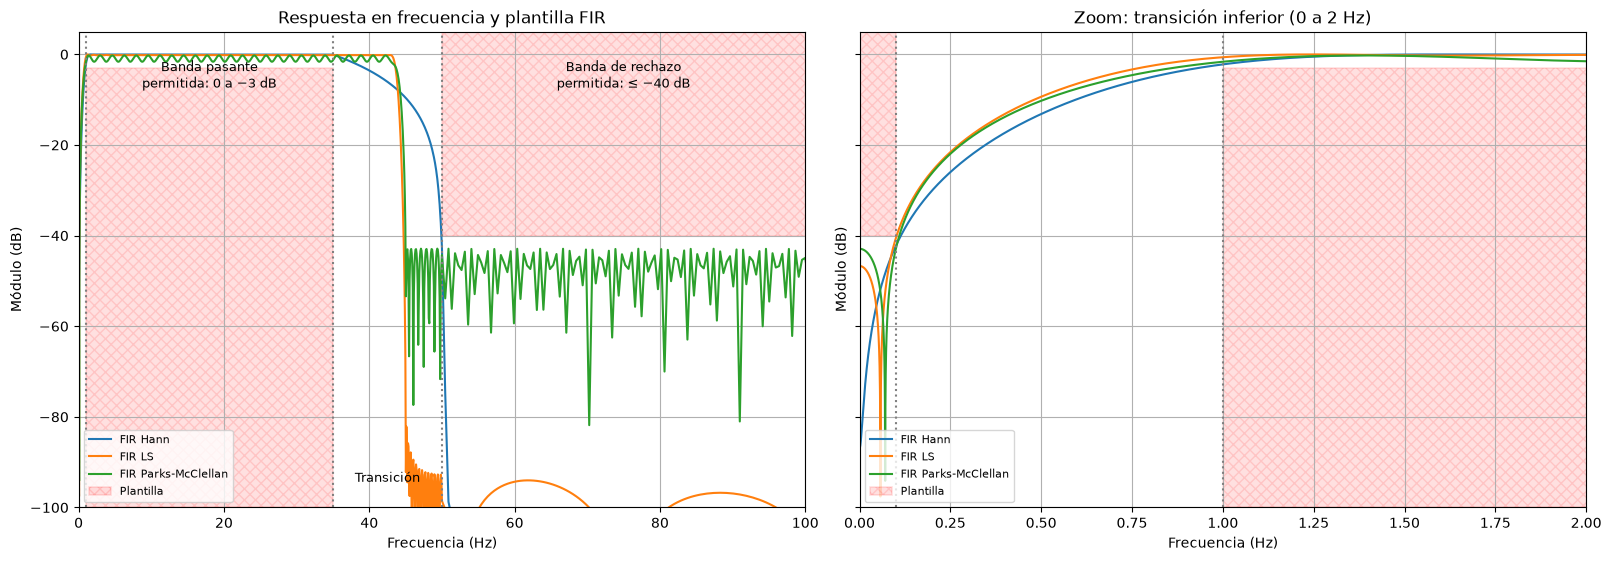

In [148]:

#%% Verificación conjunta de la plantilla FIR

fig, (ax_mod, ax_zoom) = plt.subplots(
    1, 2, figsize=(16, 5.5), sharey=True,
    constrained_layout=True
)

# Respuestas de los tres filtros FIR
filtros_fir = [
    (b_win_hann, 'FIR Hann'),
    (b_firls, 'FIR LS'),
    (b_remez, 'FIR Parks-McClellan')
]

for b, nombre in filtros_fir:

    # Reutilizamos calc_freq_fir()
    f, h = calc_freq_fir(b)

    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    ax_mod.plot(f, modulo_db, linewidth=1.5, label=nombre)
    ax_zoom.plot(f, modulo_db, linewidth=1.5, label=nombre)


# Ploteo de la plantilla original en ambos gráficos

for ax in (ax_mod, ax_zoom):

    # Banda pasante: zona no permitida por debajo de -ripple
    rect_pasante = Rectangle(
        (wp1, y_min), wp2-wp1, -ripple-y_min,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2,
        label='Plantilla'
    )
    ax.add_patch(rect_pasante)

    # Banda de rechazo: zona no permitida por encima de -att

    # Rechazo inferior
    rect_rechazo_inf = Rectangle(
        (0, -att), ws1, y_max+att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax.add_patch(rect_rechazo_inf)

    # Rechazo superior
    rect_rechazo = Rectangle(
        (ws2, -att), fs_ecg/2-ws2, y_max+att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax.add_patch(rect_rechazo)

    # Límites de la plantilla
    for borde in (ws1, wp1, wp2, ws2):
        ax.axvline(borde, color="gray", linestyle=":")

    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Módulo (dB)")
    ax.grid(True)
    ax.legend(loc="lower left", fontsize=8)


# --- Gráfico 1: plantilla completa ---

ax_mod.set_title("Respuesta en frecuencia y plantilla FIR")
ax_mod.set_xlim(0, 100)

# Etiquetas originales
ax_mod.text(
    (wp1+wp2)/2, y_max-6,
    "Banda pasante\npermitida: 0 a −3 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (ws2+100)/2, y_max-6,
    "Banda de rechazo\npermitida: ≤ −40 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (wp2+ws2)/2, y_min+5,
    "Transición",
    ha="center", va="bottom", fontsize=9
)


# --- Gráfico 2: transición inferior ---

ax_zoom.set_title("Zoom: transición inferior (0 a 2 Hz)")
ax_zoom.set_xlim(0, 2)

plt.show()



#### Análisis del cumplimiento de la plantilla

Al comparar las tres respuestas en frecuencia, se observa que **los tres filtros FIR cumplen con las restricciones de la plantilla original**, manteniendo la ganancia dentro del intervalo permitido de −3 a 0 dB en la banda pasante y alcanzando una atenuación de al menos 40 dB en ambas bandas de rechazo.

En la banda de rechazo superior, **cuadrados mínimos alcanza una atenuación considerablemente mayor** que los otros dos métodos. Sin embargo, esto no significa necesariamente que sea el filtro más conveniente, ya que los tres satisfacen la atenuación mínima exigida de 40 dB.

Por lo tanto, una vez verificado el cumplimiento de la plantilla, resulta importante comparar también la **cantidad de coeficientes y el retardo de grupo** de cada filtro, para determinar qué método permitió alcanzar las especificaciones con menor costo computacional.



### Comparación de fase y retardo de grupo

Para comparar los tres diseños FIR, se calcularon sus respuestas de fase y retardo de grupo a partir de la respuesta en frecuencia obtenida con `freqz()`.

La fase se calculó utilizando `np.angle()` y `np.unwrap()`, mientras que el retardo de grupo se obtuvo a partir de la derivada numérica de la fase mediante `np.gradient()`.

Se representaron ambas respuestas únicamente en la **banda pasante de 1 a 35 Hz**, donde interesa comprobar que los filtros mantienen un comportamiento de fase lineal y retardo constante.


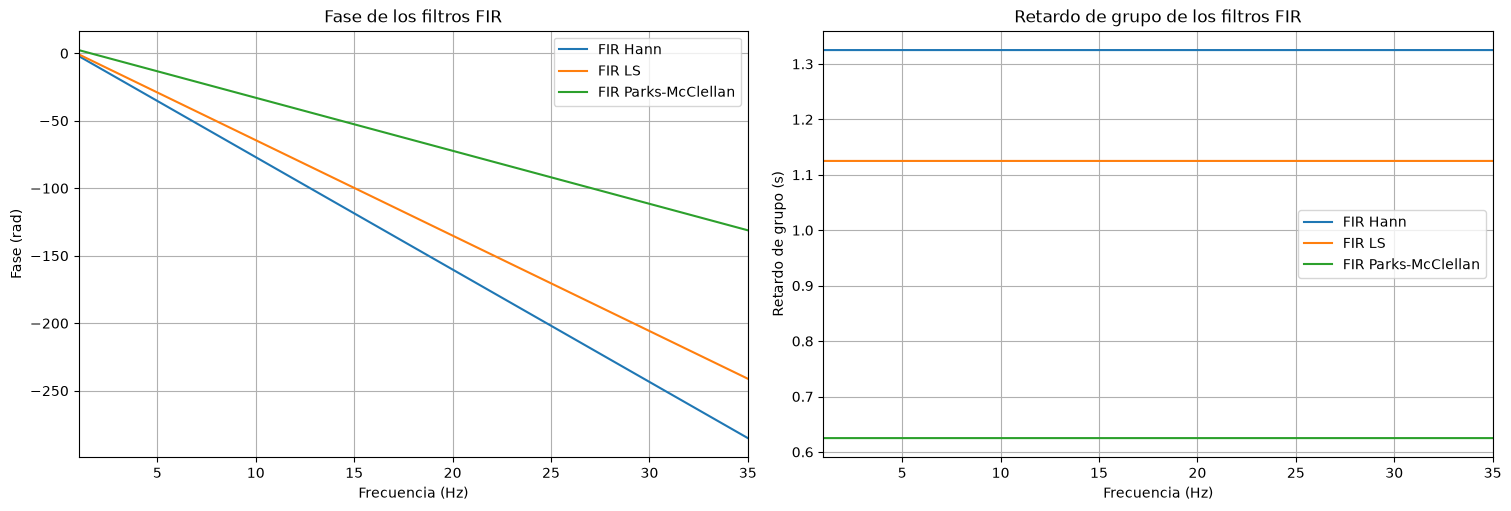

In [149]:

#%% Comparación de fase y retardo de grupo FIR

fig, (ax_fase, ax_retardo) = plt.subplots(
    1, 2, figsize=(15, 5),
    constrained_layout=True
)

filtros_fir = [
    (b_win_hann, 'FIR Hann'),
    (b_firls, 'FIR LS'),
    (b_remez, 'FIR Parks-McClellan')
]

for b, nombre in filtros_fir:

    # Respuesta en frecuencia original
    f, h = calc_freq_fir(b)

    # Analizamos únicamente la banda pasante
    banda_pasante = (f >= wp1) & (f <= wp2)

    f_paso = f[banda_pasante]
    h_paso = h[banda_pasante]

    # Fase desenrollada
    fase_rad = np.unwrap(np.angle(h_paso))

    # Retardo de grupo: -d(fase)/d(omega)
    omega = 2 * np.pi * f_paso
    retardo_s = -np.gradient(fase_rad, omega)

    # Gráficos
    ax_fase.plot(f_paso, fase_rad, label=nombre)
    ax_retardo.plot(f_paso, retardo_s, label=nombre)


# --- Fase ---

ax_fase.set_title("Fase de los filtros FIR")
ax_fase.set_xlabel("Frecuencia (Hz)")
ax_fase.set_ylabel("Fase (rad)")
ax_fase.set_xlim(wp1, wp2)
ax_fase.grid()
ax_fase.legend()


# --- Retardo de grupo ---

ax_retardo.set_title("Retardo de grupo de los filtros FIR")
ax_retardo.set_xlabel("Frecuencia (Hz)")
ax_retardo.set_ylabel("Retardo de grupo (s)")
ax_retardo.set_xlim(wp1, wp2)
ax_retardo.grid()
ax_retardo.legend()

plt.show()



### Análisis y comparación final de los filtros FIR

En los gráficos se observa que **los tres filtros presentan fase lineal y retardo de grupo constante** en la banda pasante. Para comparar su complejidad se consideraron la cantidad de coeficientes, el orden ($N-1$) y el retardo de cada diseño.

| Método | Taps (N) | Orden (N−1) | Retardo (muestras) | Retardo (segundos) |
|---|---:|---:|---:|---:|
| Hann | 2651 | 2650 | 1325 | 1,325 |
| Cuadrados mínimos | 2251 | 2250 | 1125 | 1,125 |
| Parks-McClellan | 1251 | 1250 | 625 | 0,625 |

La principal dificultad del diseño estuvo asociada a la **transición inferior de 0,1 a 1 Hz**, que exigió una cantidad elevada de coeficientes para alcanzar la atenuación solicitada.

Entre los diseños evaluados, **Parks-McClellan resultó el más eficiente**, logrando una reducción del 52,8 % de coeficientes respecto de Hann y del 44,4 % respecto de cuadrados mínimos. Esto también permitió disminuir el retardo de grupo, manteniendo la fase lineal y el cumplimiento de la plantilla.

Por lo tanto, **Parks-McClellan fue el método FIR más conveniente de los tres diseños evaluados**, considerando el cumplimiento de las especificaciones, la cantidad de coeficientes y el retardo introducido.


### Aplicación de los filtros al ECG

In [150]:
# %% Aplicar filtros al ECG

# IIR: filtrado hacia adelante y hacia atrás
ecg_butt = sig.sosfiltfilt(sos_butt, ecg_one_leadruido)
ecg_cheby2 = sig.sosfiltfilt(sos_cheby2, ecg_one_leadruido)
ecg_cauer = sig.sosfiltfilt(sos_cauer, ecg_one_leadruido)

# Aplicar filtros FIR al ECG
# ecg_win_boxcar = sig.lfilter(b_win_boxcar, 1, ecg_one_leadruido)
# ecg_win_hamming = sig.lfilter(b_win_hamming, 1, ecg_one_leadruido)
ecg_win_hann = sig.lfilter(b_win_hann, 1, ecg_one_leadruido)

# Aplicar FIRLS al ECG
ecg_firls = sig.lfilter(b_firls, 1, ecg_one_leadruido)

# Aplicar Parks-McClellan al ECG
ecg_remez = sig.lfilter(b_remez, 1, ecg_one_leadruido)

# Demora de grupo de los FIR: (N-1)/2 muestras
# Al comparar con el ECG original compensamos la demora al graficar
# demora_box = (b_win_boxcar.shape[0]-1)//2
# demora_hamm = (b_win_hamming.shape[0]-1)//2

demora_hann = (b_win_hann.shape[0]-1)//2
demora_firls = (b_firls.shape[0]-1)//2
demora_remez = (b_remez.shape[0]-1)//2

demora_max = max(demora_hann, demora_firls, demora_remez)

#### Cómo se aplican los filtros
 - IIR: `sosfiltfilt` filtra hacia adelante y hacia atrás. Anula la distorsión de fase: fase cero y retardo nulo.
 - FIR: `lfilter` es causal, así que retrasa la señal (N-1)/2 muestras. Por eso, al graficar, se suma esa demora
  al índice para que los latidos queden alineados con el ECG original.


In [151]:
# %% Función para graficar UNA región: todos juntos, o IIR y FIR lado a lado

cant_muestras = ecg_one_leadruido.shape[0]

def graficar_region(ii, etiqueta_original, modo='todos'):
    # modo: 'todos'      -> una figura con todos los filtros juntos
    #       'separados'  -> una figura con dos gráficos lado a lado: IIR (izquierda) y FIR (derecha)

    # Intervalo limitado de 0 a cant_muestras
    inicio = max(0, int(ii[0]))
    fin = min(cant_muestras, int(ii[1]))

    if inicio >= fin:
        return

    zoom_region = np.arange(inicio, fin, dtype=int)

    # FIR alineados con el ECG original (demora compensada)
    zoom_fir = zoom_region[
        zoom_region + demora_max < cant_muestras
    ]

    if modo == 'todos':

        plt.figure(figsize=(12, 5))
        plt.plot(zoom_region, ecg_one_leadruido[zoom_region],
                 label=etiqueta_original, linewidth=1.5, alpha=0.6, color='gray')

        # IIR
        plt.plot(zoom_region, ecg_cheby2[zoom_region], label='Chebyshev II', color='tab:blue')
        plt.plot(zoom_region, ecg_butt[zoom_region], label='Butterworth', color='tab:orange')
        plt.plot(zoom_region, ecg_cauer[zoom_region], label='Cauer')

        # FIR
        plt.plot(zoom_fir, ecg_win_hann[zoom_fir + demora_hann], label='FIR Hann')
        plt.plot(zoom_fir, ecg_firls[zoom_fir + demora_firls], label='FIR LS', color='tab:green')
        plt.plot(zoom_fir, ecg_remez[zoom_fir + demora_remez], label='FIR Parks-McClellan', color='tab:red')

        plt.title('Región: ' + str(inicio) + ' a ' + str(fin) + ' - todos los filtros')
        plt.ylabel('Amplitud')
        plt.xlabel('Muestras (#)')
        plt.grid()
        plt.legend()
        plt.show()

    else:

        # Dos gráficos lado a lado, con los mismos ejes para poder compararlos
        fig, (ax_iir, ax_fir) = plt.subplots(1, 2, figsize=(16, 5), sharex=True, sharey=True,
                                             constrained_layout=True)

        # ECG original en los dos
        for ax in (ax_iir, ax_fir):
            ax.plot(zoom_region, ecg_one_leadruido[zoom_region],
                    label=etiqueta_original, linewidth=1.5, alpha=0.6, color='gray')

        # Izquierda: IIR
        ax_iir.plot(zoom_region, ecg_cheby2[zoom_region], label='Chebyshev II', color='tab:green')
        ax_iir.plot(zoom_region, ecg_butt[zoom_region], label='Butterworth', color='tab:orange')
        ax_iir.plot(zoom_region, ecg_cauer[zoom_region], label='Cauer')
        ax_iir.set_title('Filtros IIR (sosfiltfilt)')

        # Derecha: FIR
        ax_fir.plot(zoom_fir, ecg_win_hann[zoom_fir + demora_hann], label='FIR Hann')
        ax_fir.plot(zoom_fir, ecg_firls[zoom_fir + demora_firls], label='FIR LS', color='tab:green')
        ax_fir.plot(zoom_fir, ecg_remez[zoom_fir + demora_remez], label='FIR Parks-McClellan', color='tab:red')
        ax_fir.set_title('Filtros FIR (lfilter, demora compensada)')

        for ax in (ax_iir, ax_fir):
            ax.set_xlabel('Muestras (#)')
            ax.grid()
            ax.legend()
        ax_iir.set_ylabel('Amplitud')

        fig.suptitle('Región: ' + str(inicio) + ' a ' + str(fin) + ' - IIR y FIR por separado')
        plt.show()

### REGIONES CON RUIDO
Interferentes: ruido de baja frecuencia (movimiento de línea de base, respiración) y de alta frecuencia (electrodos, músculo).

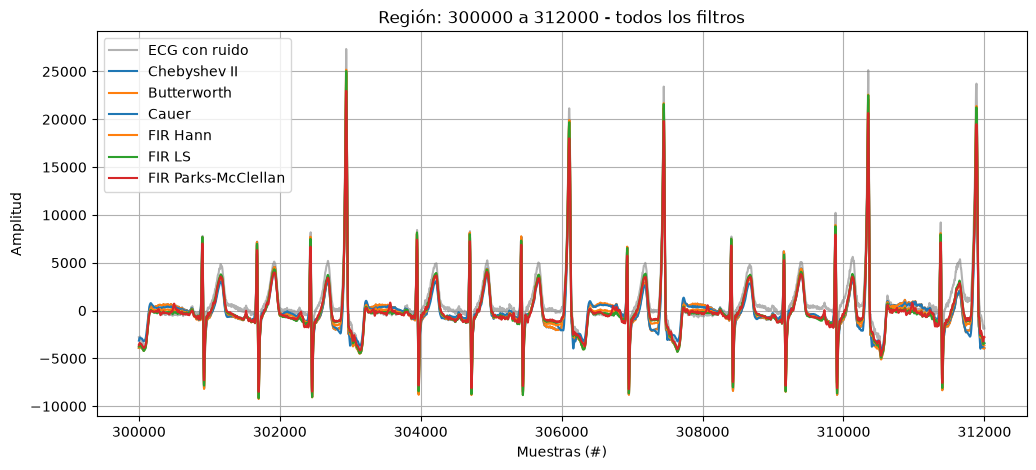

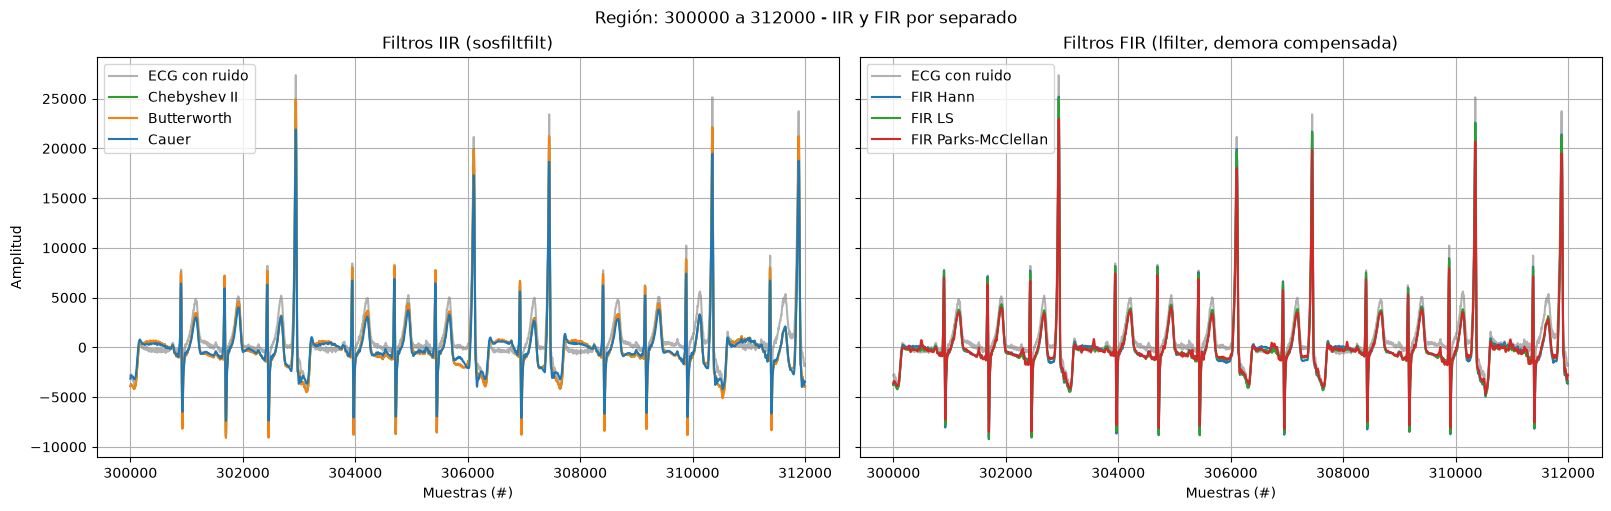

In [152]:
# %% Región con ruido 1 - todos los filtros
graficar_region(regs_con_ruido[0], 'ECG con ruido', 'todos')

# %% Región con ruido 1 - IIR y FIR lado a lado
graficar_region(regs_con_ruido[0], 'ECG con ruido', 'separados')


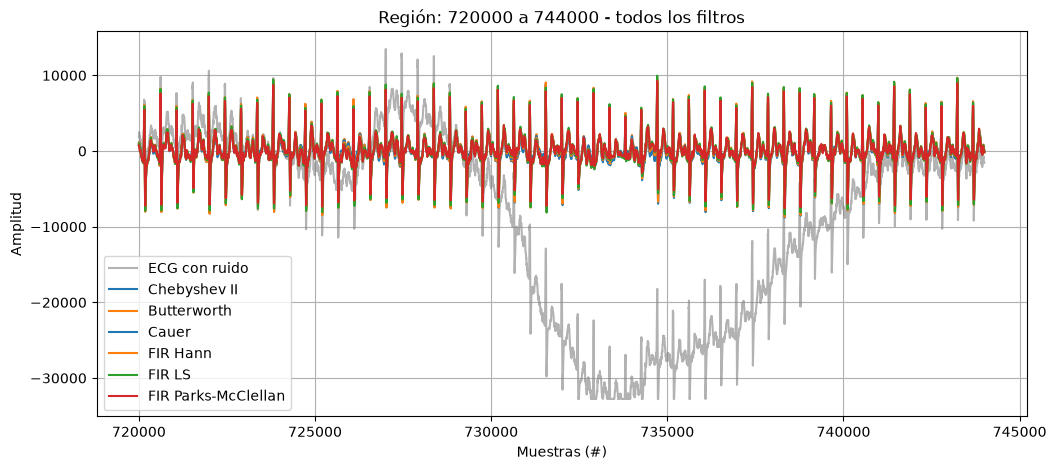

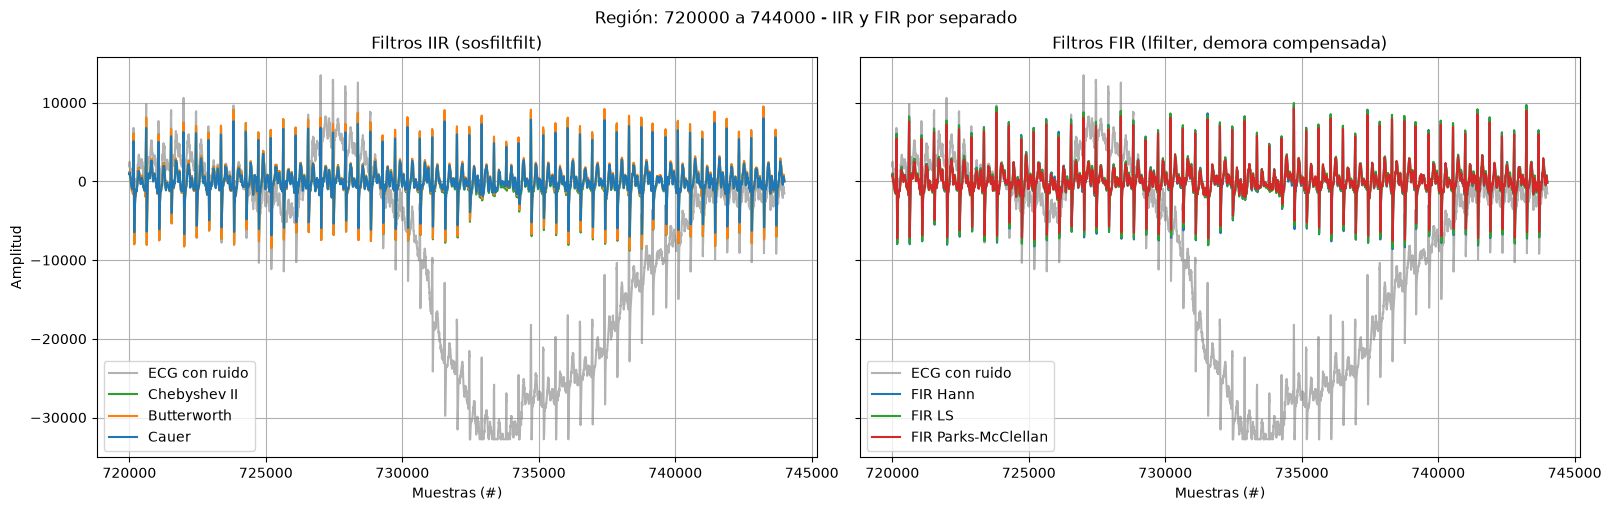

In [153]:
# %% Región con ruido 2 - todos los filtros
graficar_region(regs_con_ruido[1], 'ECG con ruido', 'todos')

# %% Región con ruido 2 - IIR y FIR lado a lado
graficar_region(regs_con_ruido[1], 'ECG con ruido', 'separados')

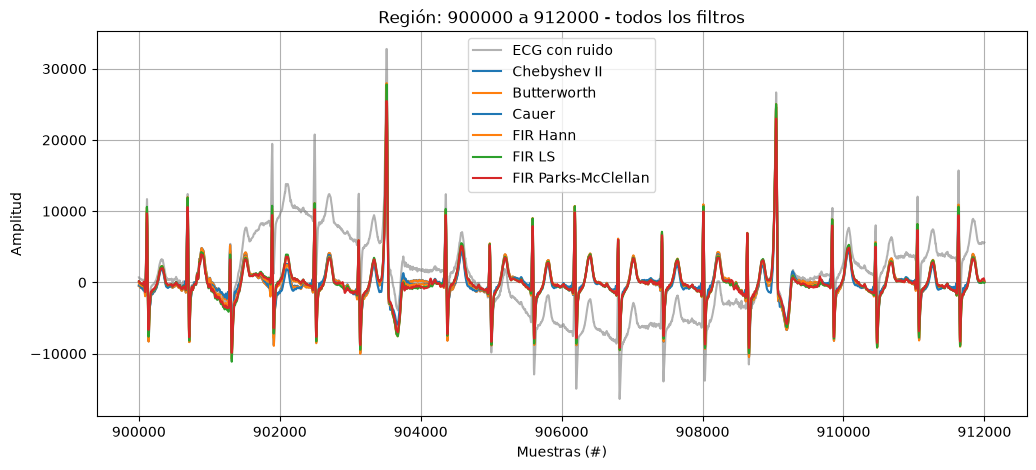

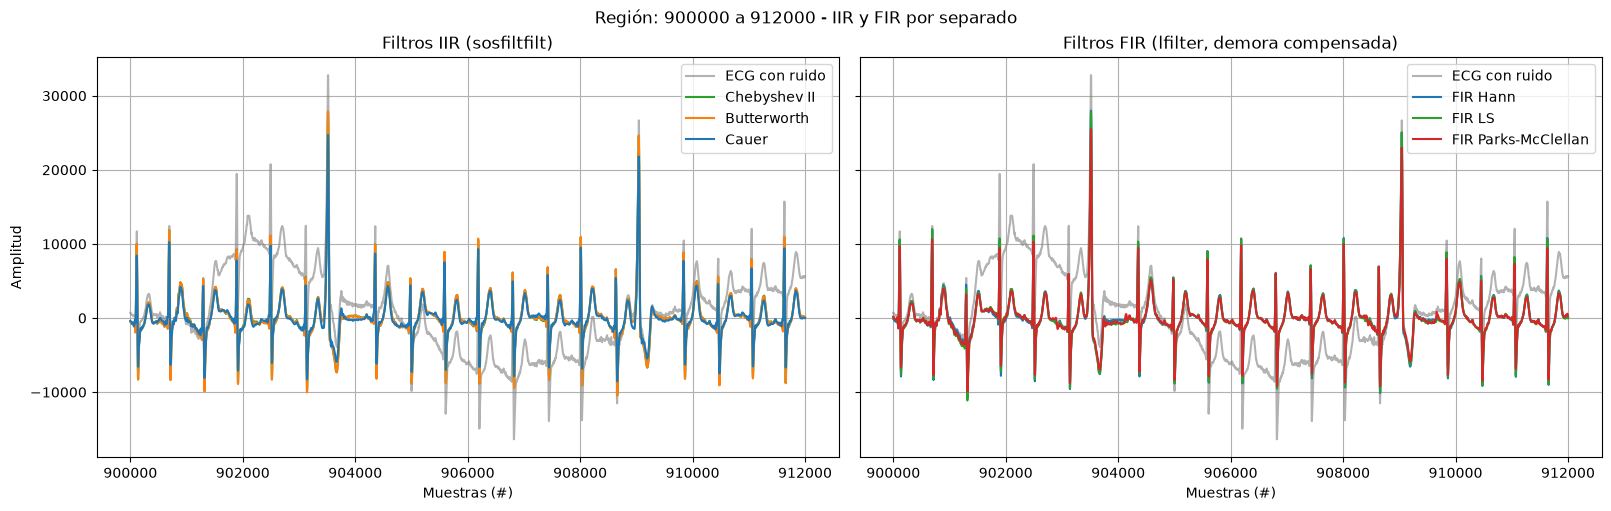

In [154]:
# %% Región con ruido 3 - todos los filtros
graficar_region(regs_con_ruido[2], 'ECG con ruido', 'todos')

# %% Región con ruido 3 - IIR y FIR lado a lado
graficar_region(regs_con_ruido[2], 'ECG con ruido', 'separados')

### Análisis - regiones con ruido

#### 1. Qué se ve en el ECG original y de dónde sale cada ruido

Al observar los gráficos se nota que en la región 1 el ECG original ya muestra un leve ruido, mientras que en las regiones 2 y 3 se aprecian fluctuaciones marcadas donde la señal sube y baja aun sin pasar por ningún filtro. Este comportamiento es el esperable en una prueba de esfuerzo, dado que a medida que avanza la prueba aumentan progresivamente el esfuerzo físico, la respiración y el movimiento del paciente.

El ruido de baja frecuencia en la línea de base ($f < 0{,}5\text{ Hz}$) corresponde a la respiración y al desplazamiento del paciente sobre la cinta ergométrica. Al respirar o moverse, toda la señal se desplaza lentamente hacia arriba y hacia abajo; no se trata de una alteración cardíaca, sino de un corrimiento del nivel de referencia que provoca la pérdida del nivel isoeléctrico. Por su parte, el ruido de alta frecuencia (visible como una rugosidad sobre las ondas P, QRS y T) proviene de la actividad mioeléctrica producida por la contracción de los músculos cercanos a los electrodos durante el ejercicio y del movimiento de los electrodos, que genera un contacto intermitente por la transpiración y el desplazamiento, sumado a la interferencia de la red eléctrica de 50 Hz.

Cabe resaltar que no todo lo que se ve distinto constituye ruido. Los latidos normales de origen sinusal presentan una onda P seguida de un complejo QRS angosto, mientras que un latido de origen ventricular se manifiesta sin onda P previa, con el QRS más ancho y deformado y con la onda T en sentido opuesto. Estas manifestaciones pueden presentarse durante el esfuerzo y representan un fenómeno fisiológico real del corazón, no una interferencia. Por este motivo, el filtro no debe eliminarlos ni deformarlos, contando en el archivo con `heartbeat_pattern1` (normal) y `heartbeat_pattern2` (ventricular) como referencias morfológicas.

#### 2. Qué hacen los IIR (Butterworth, Chebyshev II, Cauer) en las tres regiones

Los filtros IIR corrigen con eficacia el desnivel de la línea de base y reubican la señal centrada en el cero isoeléctrico, gracias a la fuerte atenuación provista en la banda de rechazo inferior ($f \le 0{,}1\text{ Hz}$). En cuanto a la preservación temporal, al implementarse mediante `sosfiltfilt` (filtrado bidireccional hacia adelante y hacia atrás), la fase se cancela por completo ($\theta(\omega) = 0$), garantizando que los complejos QRS no presenten desplazamiento temporal respecto de la señal original. Asimismo, logran una adecuada atenuación en alta frecuencia al suprimir la rugosidad muscular y dejar los contornos de las ondas limpios y suaves.

#### 3. Qué hacen los FIR (Hann, LS, Parks-McClellan) en las tres regiones

Los filtros FIR eliminan la oscilación lenta de baja frecuencia con una eficacia equivalente a la de los IIR, restituyendo el trazo sobre el eje horizontal. Al tratarse de filtros causales introducen un retardo de grupo constante $\tau = (N-1)/2$ muestras; sin embargo, al compensar dicha demora en el gráfico (`zoom_region + demora`), los latidos filtrados calzan de manera exacta sobre los picos del ECG original.

#### 4. Diferencias entre IIR y FIR, y entre los filtros de una misma familia

Al comparar ambas familias, se comprueba que los dos enfoques logran una limpieza visual prácticamente idéntica en el dominio temporal, debido a que ambos satisfacen la misma plantilla espectral. La diferencia fundamental radica en la complejidad computacional: los IIR consiguen este desempeño con un orden muy bajo (orden 6 a 8), mientras que los FIR demandaron entre 1251 y 2651 coeficientes, implicando una carga de cálculo y un uso de memoria considerablemente mayores.

Entre los filtros IIR, Butterworth ofrece la transición más suave en la banda de paso, mientras que Cauer y Chebyshev II presentan caídas más abruptas en la transición; gracias al filtrado bidireccional, ninguno introduce distorsión de fase observable en el trazo. Dentro de la familia FIR, la ventana de Hann ($N=2651$) proporciona un trazo sumamente suave por la rápida caída de los lóbulos secundarios de la ventana, los cuadrados mínimos ($N=2251$) ocupan una posición intermedia en cantidad de coeficientes, y Parks-McClellan ($N=1251$) resulta el más eficiente al satisfacer la plantilla con menos de la mitad de coeficientes que Hann, alcanzando una supresión de ruido equivalente con aproximadamente la mitad del retardo temporal ($625\text{ ms}$ frente a $1325\text{ ms}$).

#### 5. Conclusiones

Ambos métodos demuestran ser eficaces para mitigar la deriva extrema de la línea de base y el ruido de alta frecuencia en las tres regiones evaluadas. Dado que los filtros actúan por bandas de frecuencia y no distinguen el tipo de latido, no eliminan los latidos atípicos (como los de origen ventricular), que constituyen información clínica real del paciente. No obstante, reducir el ruido no garantiza por sí solo que la morfología se conserve idéntica: la evaluación de la inocuidad sobre la amplitud y la forma de las ondas se realiza en las regiones sin ruido, donde se observan diferencias de amplitud entre algunos métodos.

### REGIONES SIN RUIDO

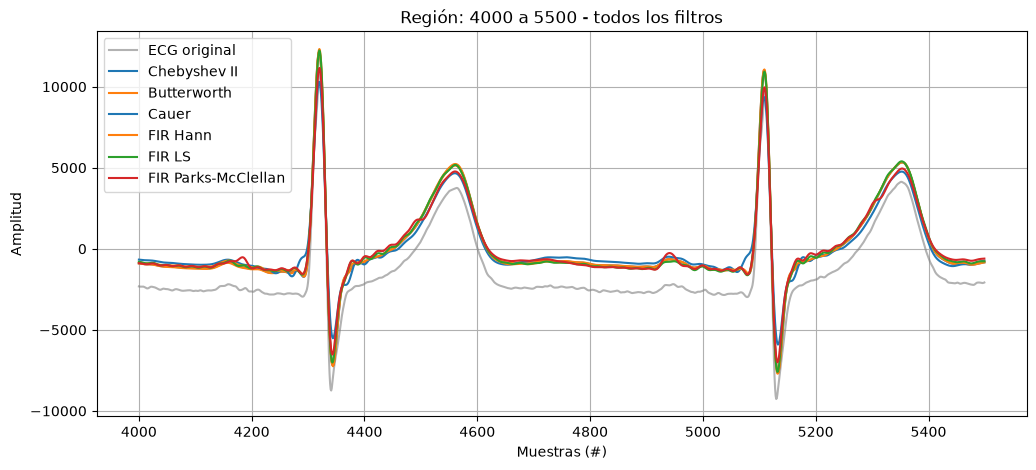

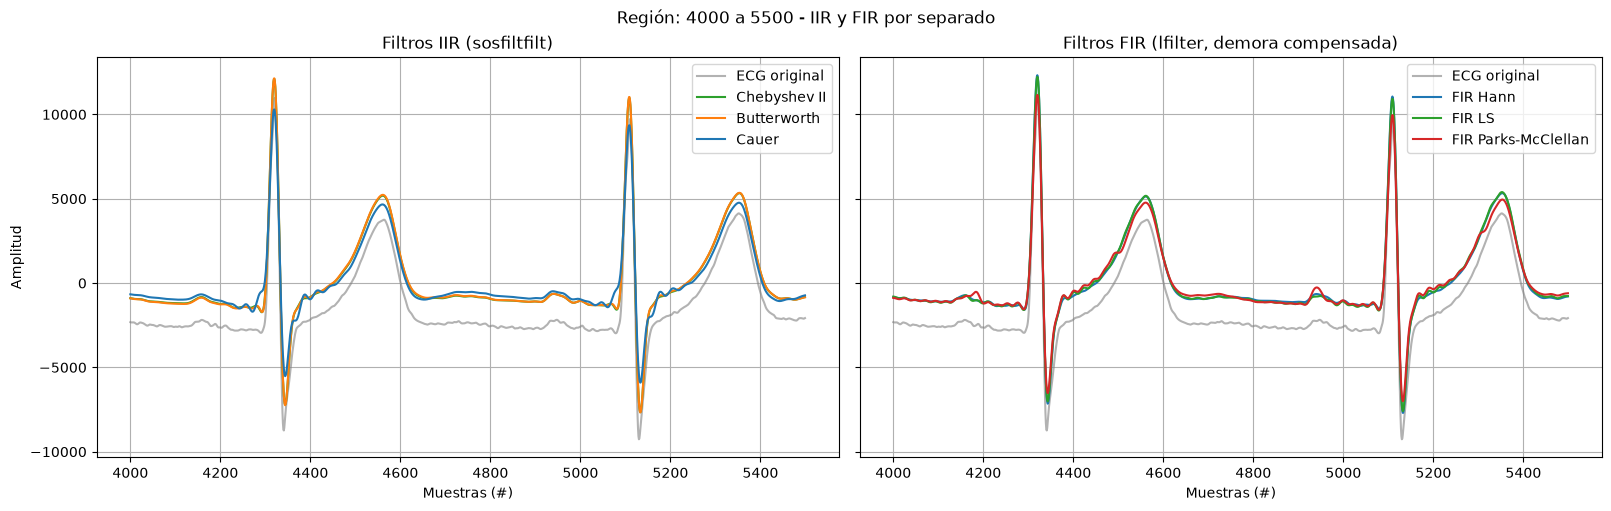

In [155]:
# %% Región sin ruido 1 - todos los filtros
graficar_region(regs_sin_ruido[0], 'ECG original', 'todos')

# %% Región sin ruido 1 - IIR y FIR lado a lado
graficar_region(regs_sin_ruido[0], 'ECG original', 'separados')

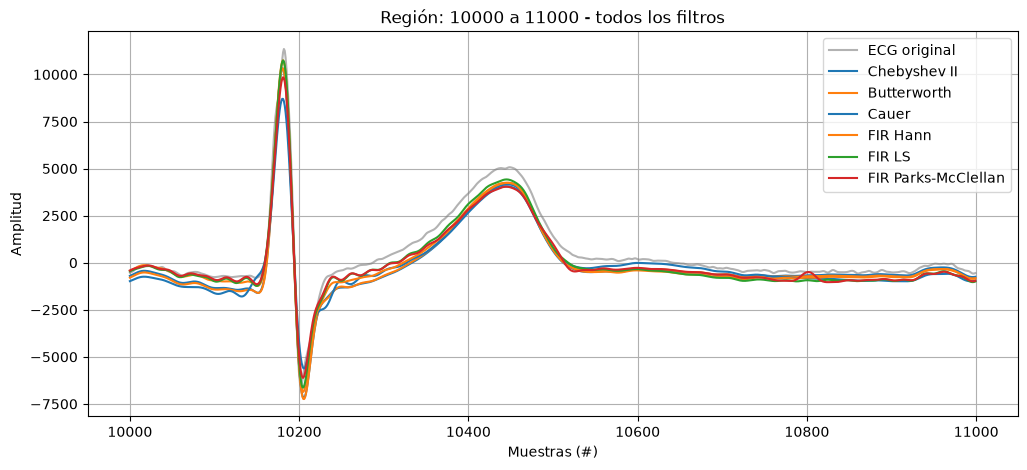

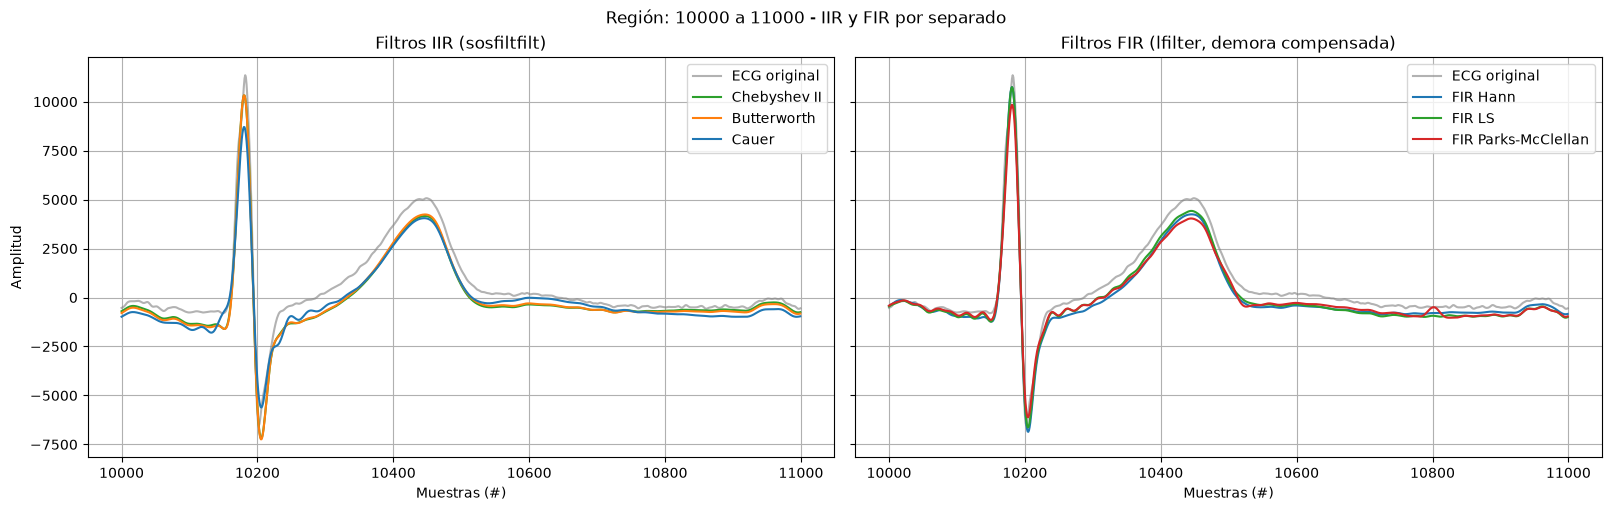

In [156]:
# %% Región sin ruido 2 - todos los filtros
graficar_region(regs_sin_ruido[1], 'ECG original', 'todos')

# %% Región sin ruido 2 - IIR y FIR lado a lado
graficar_region(regs_sin_ruido[1], 'ECG original', 'separados')

### Análisis - región sin ruido 

#### 1. Comportamiento del segmento ST: 

Al comparar el segmento ST, que es la zona que viene inmediatamente después de cada pico alto del latido y antes de la siguiente onda, se observa que en el ECG original el registro no es perfectamente horizontal, sino que presenta una suave pendiente ascendente natural propia del paciente. Al superponer las salidas de todos los filtros diseñados sobre la señal sin procesar, se comprueba que tanto los IIR como los FIR respetan fielmente esa trayectoria original sin introducir pendientes falsas, curvaturas artificiales ni desniveles respecto a la línea de base. Esto se debe a que ninguno de los métodos genera distorsión de fase en las componentes lentas: los IIR anulan la fase mediante el filtrado bidireccional (sosfiltfilt), mientras que los FIR garantizan retardo idéntico para todas las frecuencias gracias a su fase estrictamente lineal.

#### 2. Comportamiento general de amplitud:

Se aprecia que todas las salidas filtradas presentan una amplitud de pico ligeramente menor que la del ECG original sin procesar. Esto no constituye una deformación patológica del complejo QRS, sino la eliminación efectiva de la componente continua y las oscilaciones lentas de fondo que "inflaban" artificialmente el valor absoluto de la señal.

#### 3. Diferencias entre filtros: 

En el pico R: Los filtros IIR (Butterworth y Chebyshev II) y los FIR Hann y LS conservan la agudeza del vértice del QRS prácticamente intacta. En cambio, en Parks-McClellan (Remez) se observa un achatamiento sutil en la punta de la espiga R, producto de que su aproximación equiripple con menor cantidad de coeficientes ($N=1251$) ajusta la transición de forma más abrupta cerca de $35\text{ Hz}$, atenuando ligeramente las componentes armónicas más altas del complejo.
En el reposo isoeléctrico (segmento TP entre latidos): Se aprecian diferencias claras dentro de los propios IIR. Mientras que Butterworth y Chebyshev II aplanan de forma absoluta la señal dejando una línea de base completamente lisa, el filtro Cauer presenta pequeñas fluctuaciones residuales. Esto responde a su diseño elíptico con rizado constante (equiripple) en la banda de parada: al no decaer monótonamente hacia cero, deja pasar un mínimo remanente de alta frecuencia que Butterworth suprime por completo. Los filtros FIR se ubican en una posición intermedia, con un residuo de alta frecuencia apenas perceptible.

#### 4. Conclusiones:

No se observan oscilaciones parásitas ni fenómeno de Gibbs perceptible. Ninguno de los filtros introduce rebotes alrededor de las transiciones rápidas del QRS, lo que confirma que las bandas de transición fueron adecuadamente dimensionadas y que las ventanas aplicadas amortiguan de forma efectiva los lóbulos secundarios.

Los latidos quedan en perfecta coincidencia temporal. En los IIR, la alineación es nativa por el retardo nulo que introduce sosfiltfilt. En los FIR, tras aplicar la compensación del retardo de grupo constante (zoom_region + demora, con $\tau = (N-1)/2$ muestras), los latidos calzan de forma exacta sobre los picos originales.

Ambos enfoques demuestran una elevada inocuidad clínica, preservando las relaciones temporales y morfológicas fundamentales del trazado. Respecto a la selección del mejor diseño en cada familia: En los IIR, el mejor resultado lo ofrece Butterworth: a pesar de que Cauer requiere un orden teórico menor, su rizado genera pequeñas oscilaciones en la línea de base. Butterworth, al ser maximalmente plano en la banda de paso y tener decaimiento suave y continuo en la de rechazo, entrega el trazo más limpio, homogéneo y fiel a la señal biológica. En los FIR, el mejor compromiso lo alcanza Parks-McClellan (Remez): es el más eficiente de los métodos no recursivos, cumpliendo con la exigente plantilla de la cátedra con casi la mitad de coeficientes que la ventana de Hann ($N=1251$ frente a $2651$), lo que reduce la latencia temporal a la mitad ($0{,}625\text{ s}$ vs. $1{,}325\text{ s}$) y optimiza drásticamente el costo de cómputo.

### RESPUESTA AL IMPULSO

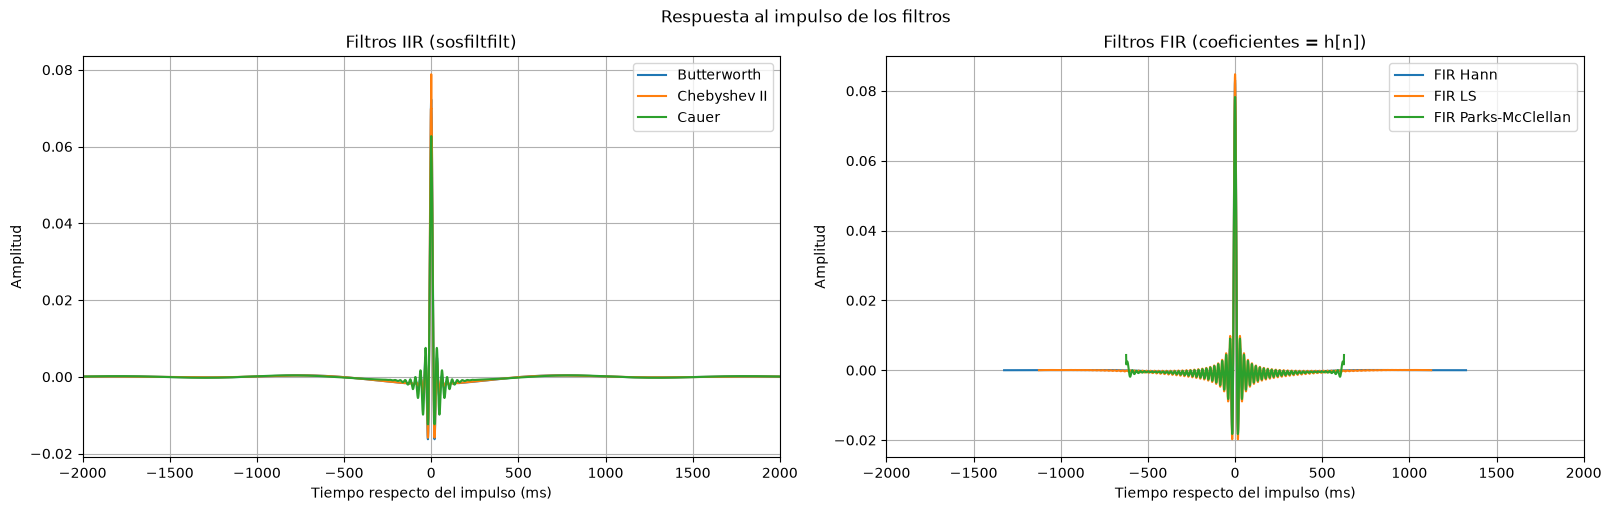

In [157]:
#%% Respuesta al impulso - Comparación de filtros (IIR a la izquierda, FIR a la derecha)

# Impulso ubicado en el centro para evitar efectos de borde
cant_imp = 20000
centro_imp = cant_imp // 2

delta_k = np.zeros(cant_imp)
delta_k[centro_imp] = 1

# Respuesta al impulso IIR
# Mismo filtrado que aplicamos al ECG
resp_imp_butt = sig.sosfiltfilt(sos_butt, delta_k)
resp_imp_cheby2 = sig.sosfiltfilt(sos_cheby2, delta_k)
resp_imp_cauer = sig.sosfiltfilt(sos_cauer, delta_k)

# Eje temporal IIR, centrado en el impulso
t_iir = (np.arange(cant_imp) - centro_imp) / fs_ecg * 1000

# Respuesta al impulso FIR: los coeficientes b son h[n]
# Compensamos la demora para comparar los filtros alineados
t_hann = (np.arange(len(b_win_hann)) - demora_hann) / fs_ecg * 1000
t_firls = (np.arange(len(b_firls)) - demora_firls) / fs_ecg * 1000
t_remez = (np.arange(len(b_remez)) - demora_remez) / fs_ecg * 1000

# Dos gráficos lado a lado: IIR a la izquierda, FIR a la derecha
fig, (ax_iir, ax_fir) = plt.subplots(1, 2, figsize=(16, 5), sharex=True,
                                     constrained_layout=True)

# IIR
ax_iir.plot(t_iir, resp_imp_butt, label='Butterworth')
ax_iir.plot(t_iir, resp_imp_cheby2, label='Chebyshev II')
ax_iir.plot(t_iir, resp_imp_cauer, label='Cauer')
ax_iir.set_title('Filtros IIR (sosfiltfilt)')

# FIR
ax_fir.plot(t_hann, b_win_hann, label='FIR Hann')
ax_fir.plot(t_firls, b_firls, label='FIR LS')
ax_fir.plot(t_remez, b_remez, label='FIR Parks-McClellan')
ax_fir.set_title('Filtros FIR (coeficientes = h[n])')

for ax in (ax_iir, ax_fir):
    ax.set_xlim(-2000, 2000)
    ax.set_xlabel('Tiempo respecto del impulso (ms)')
    ax.set_ylabel('Amplitud')
    ax.grid()
    ax.legend()

fig.suptitle('Respuesta al impulso de los filtros')
plt.show()

### Análisis - respuesta al impulso

#### 1. Forma de h[n] en los IIR:
Al mirar el gráfico de los IIR, se observa que la respuesta no se interrumpe de forma abrupta, sino que se prolonga a lo largo de todo el eje temporal (extendiéndose más allá de las 2000 muestras) debido a la naturaleza recursiva de los sistemas IIR, cuya respuesta decae asintóticamente sin anularse estrictamente en un número finito de muestras. Sin embargo, gracias al filtrado bidireccional (sosfiltfilt), la respuesta resultante es perfectamente simétrica y centrada respecto al instante de excitación ($n = 0$), extendiéndose en espejo hacia adelante y hacia atrás. Esta simetría temporal cancela la fase del sistema, logrando fase cero estricta y retardo nulo.

#### 2. Forma de h[n] en los FIR (simétrica, fase lineal) y duración de cada uno:
A diferencia de los IIR, los filtros FIR tienen una respuesta de duración estrictamente finita: nacen en cero, se concentran en una zona central y se cortan a cero de manera exacta al cumplirse su orden $N$. Los tres son de Tipo I, exhibiendo simetría respecto a su punto medio $\tau = (N-1)/2$, lo que garantiza fase estrictamente lineal. En el trazado se aprecian diferencias claras en su forma y longitud. Ventana Hann ($N = 2651$ coeficientes, $2{,}651\text{ s}$): Posee la respuesta más extendida, pero con extremos muy suaves y lisos que decaen progresivamente a cero. Cuadrados Mínimos ($N = 2251$ coeficientes, $2{,}251\text{ s}$): Presenta una longitud intermedia y un perfil igualmente amortiguado en los extremos. Parks-McClellan / Remez ($N = 1251$ coeficientes, $1{,}251\text{ s}$): Es el más compacto de todos (corta a la mitad de muestras que Hann). Al optimizar el error en sentido minimax, no decae tan suavemente hacia los bordes: se observa un pequeño pico o lóbulo terminal justo antes de truncarse bruscamente en la muestra 1251, lo que le permite alcanzar una selectividad extrema con muchos menos coeficientes.
El filtro con la respuesta más extendida es el FIR por ventana Hann ($N = 2651$). Al ser un filtro causal, el retardo temporal es proporcional a la longitud de $h[n]$. Hann impone una demora de grupo de $1325$ muestras ($1{,}325\text{ segundos}$), más del doble que Parks-McClellan ($625$ muestras o $0{,}625\text{ s}$). Aunque una longitud elevada suele asociarse a oscilaciones parásitas (ringing), el decaimiento suave y progresivo de la ventana Hann en los extremos minimiza el ringing alrededor de transitorios abruptos como el pico R. En contrapartida, un $N$ tan grande introduce un transitorio de encendido muy prolongado ($2650$ muestras iniciales fuera de régimen).

#### Conclusiones: 
La respuesta al impulso pone en evidencia gráfica la diferencia fundamental entre ambos métodos: mientras los IIR logran una respuesta compacta y sin retardo temporal mediante el cómputo bidireccional (prolongándose suavemente en el tiempo sin truncamiento forzado), los FIR pagan el costo de la fase lineal con respuestas que deben extenderse miles de muestras para poder alcanzar una banda de transición tan angosta ($1\text{ Hz}$). Entre los FIR, Parks-McClellan demostró ser el más eficiente, cortando su respuesta a la mitad de duración que los diseños basados en ventanas.


### Conclusión

El trabajo permitió diseñar y comparar distintas metodologías de filtrado digital para reducir las interferencias presentes en un registro de ECG de una prueba de esfuerzo, considerando tanto el cumplimiento de las especificaciones en frecuencia como la conservación de la morfología cardíaca.

La principal dificultad del diseño estuvo asociada a la **transición inferior de la plantilla, entre 0,1 y 1 Hz**, necesaria para atenuar el movimiento de la línea de base. Esta exigencia condicionó especialmente los diseños FIR, que requirieron una cantidad elevada de coeficientes para alcanzar la atenuación solicitada.

Dentro de los **filtros FIR**, Parks-McClellan resultó el método más eficiente en cantidad de coeficientes, ya que permitió cumplir la plantilla con 1251 taps, frente a los 2251 de cuadrados mínimos y los 2651 de Hann. Los tres presentaron fase lineal y retardo de grupo constante, aunque con diferentes demoras. Sin embargo, al aplicarlos sobre el ECG, se observó que Parks-McClellan producía una mayor reducción de la amplitud de algunos picos R, lo que demuestra que cumplir la plantilla no garantiza una conservación idéntica de la señal.

Por su parte, los **filtros IIR** permitieron alcanzar las especificaciones con órdenes considerablemente menores. Se utilizó la implementación SOS para mejorar la robustez numérica y el filtrado bidireccional mediante `sosfiltfilt()` para obtener una respuesta efectiva de fase cero. Esta estrategia evita el desfase neto, aunque requiere un procesamiento no causal.

En el análisis temporal, los filtros consiguieron **reducir el movimiento de la línea de base y suavizar las fluctuaciones rápidas**, manteniendo reconocibles los complejos QRS y las principales ondas del ECG. No se identificaron oscilaciones parásitas importantes en las regiones examinadas, aunque sí se observaron diferencias de amplitud entre algunos métodos. Por lo tanto, la evaluación de la inocuidad debe considerar estas modificaciones y no únicamente la reducción del ruido.

**Para el procesamiento de este registro, se seleccionaría el filtro IIR Butterworth implementado mediante `sosfiltfilt()`**, ya que ofrece un buen equilibrio entre reducción de interferencias, conservación visual de la morfología y menor complejidad de implementación respecto de los FIR diseñados.

Esta elección resulta adecuada cuando se dispone del registro completo y no se requiere procesar la señal en tiempo real. Para una implementación causal que exija fase lineal, los FIR constituyen una alternativa, destacándose Parks-McClellan por su menor cantidad de coeficientes y retardo dentro de los diseños evaluados.

En definitiva, **la elección del filtro depende tanto de las especificaciones frecuenciales como de las condiciones de implementación y de la información cardíaca que se necesita preservar**.


## Bibliografía

- Holton, T. (2021). *Digital signal processing: Principles and applications*. Cambridge University Press. https://doi.org/10.1017/9781108290050
- Oppenheim, A. V., & Schafer, R. W. (2010). *Discrete-Time Signal Processing* (3rd ed.). Pearson.
- NumPy user guide — NumPy Manual. Numpy.org. https://numpy.org/doc/stable/user/index.html
- Signal processing (`scipy.signal`) — SciPy Manual. Scipy.org. https://docs.scipy.org/doc/scipy/reference/signal.html
